In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df=pd.read_csv(r"D:\tasks\egypt_House_prices(Target column Price).csv")
df.head()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,Duplex,4000000,3,3,400,No,7,Unknown,Cash,Ready to move,Finished,Nasr City
1,Apartment,4000000,3,3,160,No,10+,Unknown,Cash,Ready to move,Finished,Camp Caesar
2,Apartment,2250000,3,2,165,No,1,Unknown,Cash,Ready to move,Finished,Smoha
3,Apartment,1900000,3,2,230,No,10,Unknown,Cash,Ready to move,Finished,Nasr City
4,Apartment,5800000,2,3,160,No,Ground,Eastown,Cash,Ready to move,Semi Finished,New Cairo - El Tagamoa


In [6]:
df.shape

(27361, 12)

In [7]:
df.columns

Index(['Type', 'Price', 'Bedrooms', 'Bathrooms', 'Area', 'Furnished', 'Level',
       'Compound', 'Payment_Option', 'Delivery_Date', 'Delivery_Term', 'City'],
      dtype='str')

In [8]:
df.describe()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
count,27179,27302,26938,26988,26824,27267,27284,27219,27115,27258,27286,27334
unique,11,4180,12,12,785,3,14,559,4,10,5,183
top,Apartment,3000000,3,2,120,No,Unknown,Unknown,Cash or Installment,Ready to move,Finished,New Cairo - El Tagamoa
freq,8341,311,11677,9098,661,16447,10387,11013,10752,12094,14352,6771


In [9]:
df.isnull().sum().sort_values(ascending=False)

Area              537
Bedrooms          423
Bathrooms         373
Payment_Option    246
Type              182
Compound          142
Delivery_Date     103
Furnished          94
Level              77
Delivery_Term      75
Price              59
City               27
dtype: int64

In [10]:
df.select_dtypes(include='string').columns

Index(['Type', 'Price', 'Bedrooms', 'Bathrooms', 'Area', 'Furnished', 'Level',
       'Compound', 'Payment_Option', 'Delivery_Date', 'Delivery_Term', 'City'],
      dtype='str')

In [11]:
df.duplicated().sum()

np.int64(1909)

In [12]:
df.drop_duplicates(inplace=True)
df.reset_index(drop=True,inplace=True)

In [13]:
df.duplicated().sum()

np.int64(0)

In [14]:
df[df.isnull()].head()

,Type,Price,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [15]:
df['Price'] = pd.to_numeric(df['Price'], errors='coerce')
df.dropna(subset=['Price'], inplace=True)
df.reset_index(drop=True, inplace=True)

In [16]:
plot_df = df.copy()
for col in ['Price', 'Bedrooms', 'Bathrooms', 'Area']:
    plot_df[col] = pd.to_numeric(plot_df[col], errors='coerce')
plot_df['Price_Millions'] = plot_df['Price'] / 1_000_000


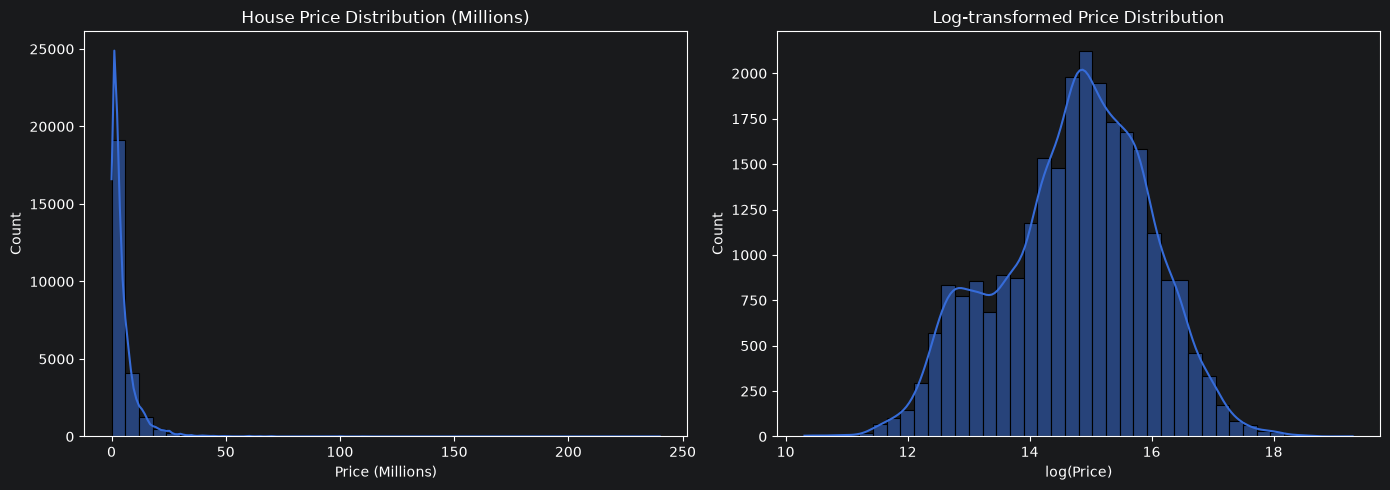

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(plot_df['Price_Millions'].dropna(), bins=40, kde=True, ax=axes[0])
axes[0].set_title('House Price Distribution (Millions)')
axes[0].set_xlabel('Price (Millions)')
sns.histplot(np.log1p(plot_df['Price'].dropna()), bins=40, kde=True, ax=axes[1])
axes[1].set_title('Log-transformed Price Distribution')
axes[1].set_xlabel('log(Price)')
plt.tight_layout()
plt.show()


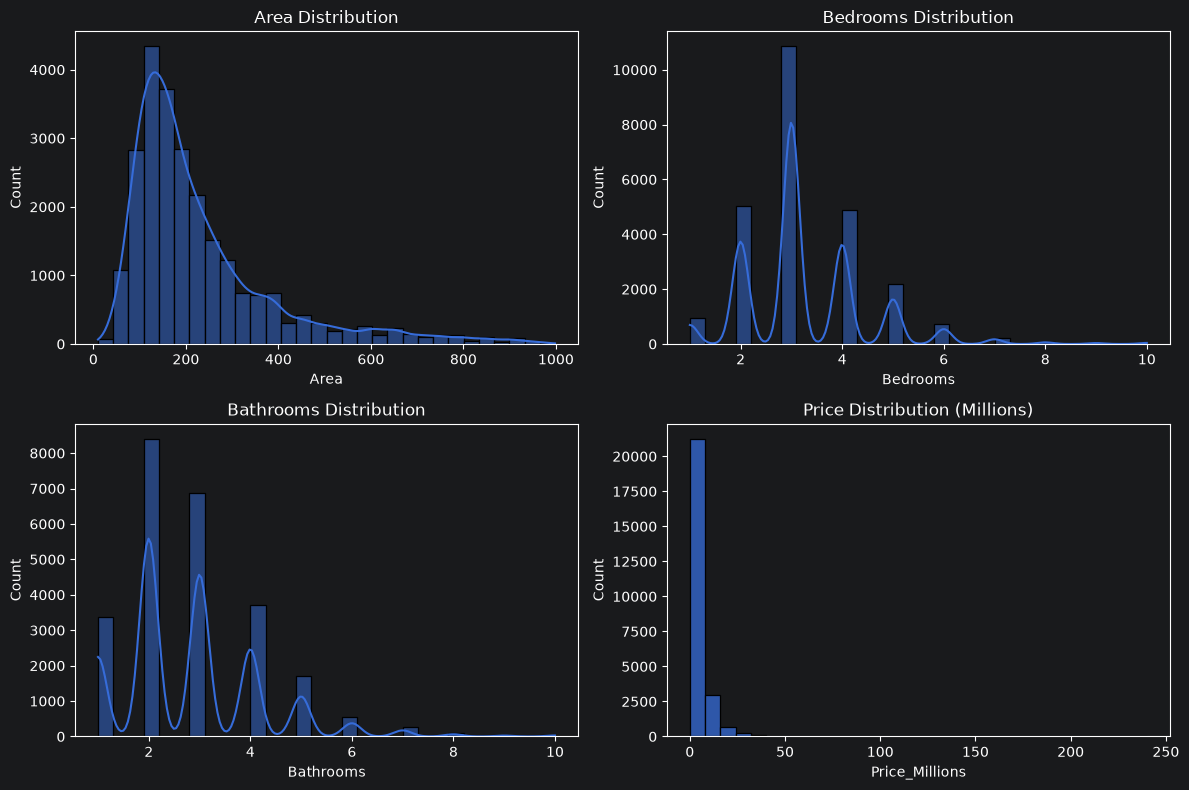

In [18]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for col, ax in zip(['Area', 'Bedrooms', 'Bathrooms'], axes.flat[:3]):
    sns.histplot(plot_df[col].dropna(), bins=30, kde=True, ax=ax)
    ax.set_title(f'{col} Distribution')
sns.histplot(plot_df['Price_Millions'].dropna(), bins=30, ax=axes.flat[3])
axes.flat[3].set_title('Price Distribution (Millions)')
plt.tight_layout()
plt.show()


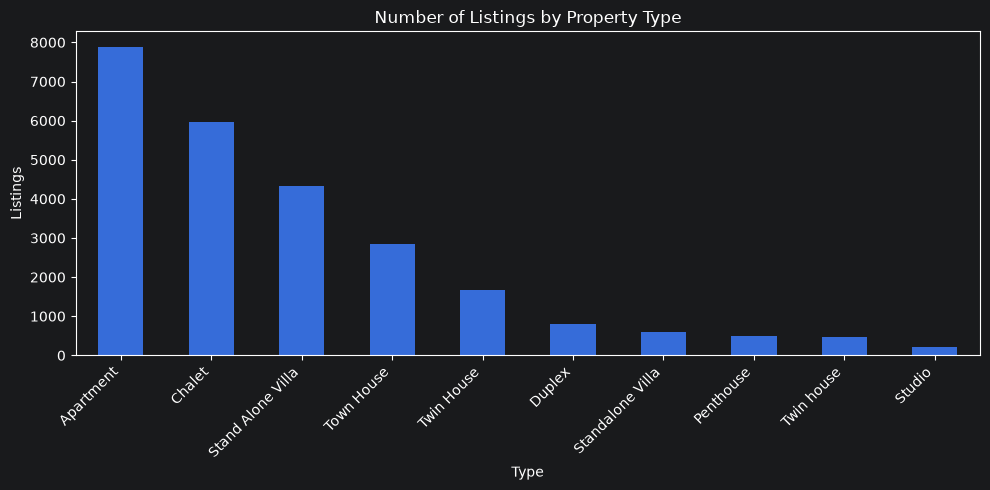

In [19]:
plt.figure(figsize=(10, 5))
plot_df['Type'].value_counts().head(15).plot(kind='bar')
plt.title('Number of Listings by Property Type')
plt.ylabel('Listings')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


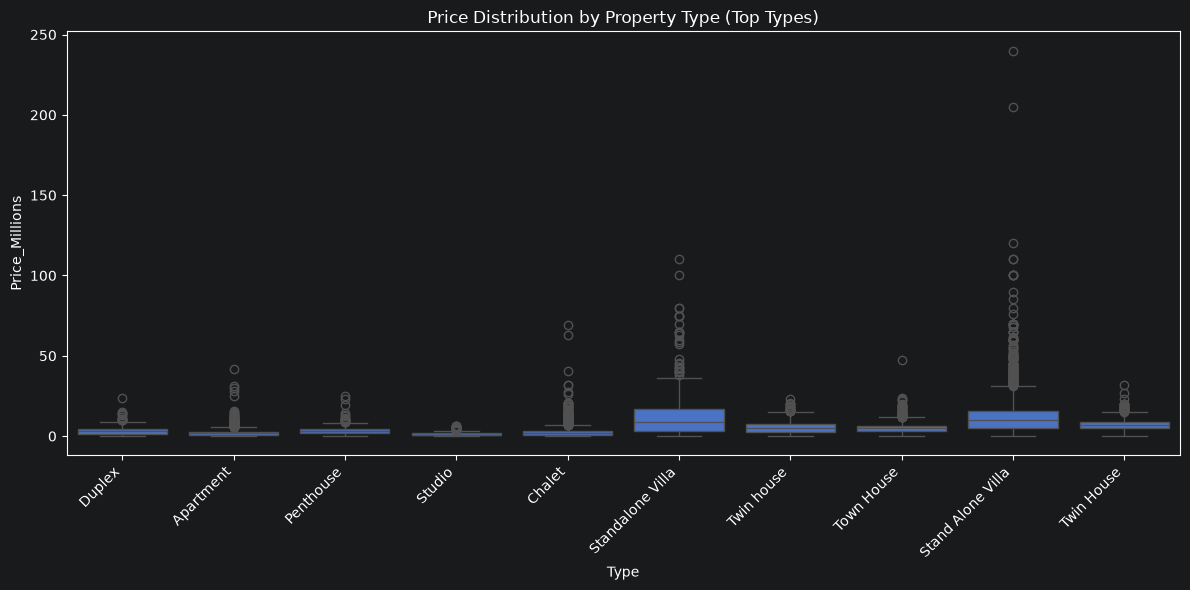

In [20]:
plt.figure(figsize=(12, 6))
top_types = plot_df['Type'].value_counts().head(10).index
sns.boxplot(data=plot_df[plot_df['Type'].isin(top_types)], x='Type', y='Price_Millions')
plt.title('Price Distribution by Property Type (Top Types)')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


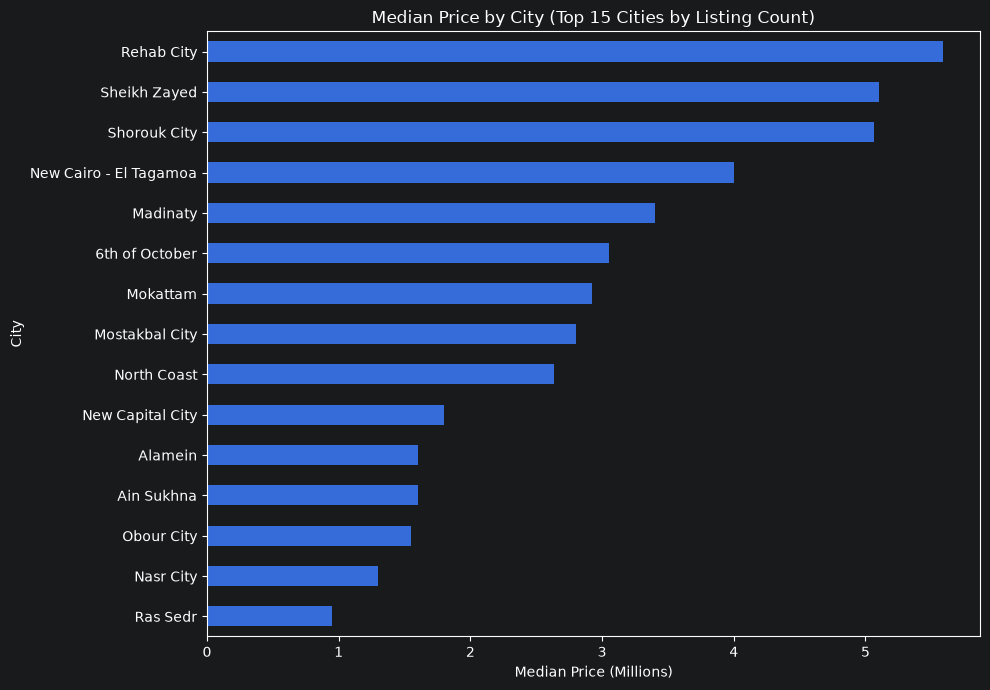

In [21]:
top_cities = plot_df['City'].value_counts().head(15).index
city_median = plot_df[plot_df['City'].isin(top_cities)].groupby('City')['Price_Millions'].median().sort_values()
plt.figure(figsize=(10, 7))
city_median.plot(kind='barh')
plt.title('Median Price by City (Top 15 Cities by Listing Count)')
plt.xlabel('Median Price (Millions)')
plt.tight_layout()
plt.show()


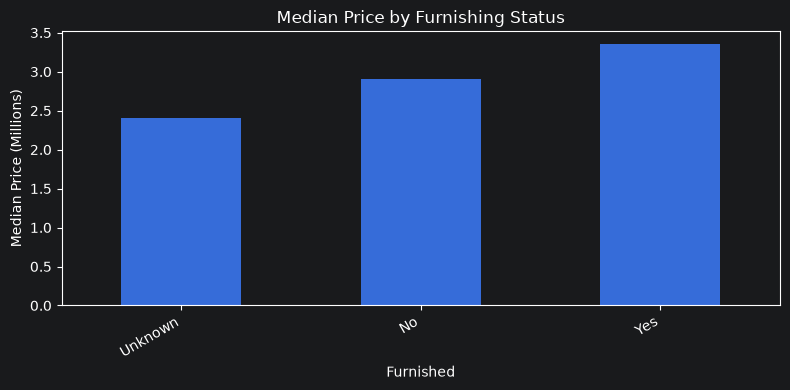

In [22]:
furn_price = plot_df.groupby('Furnished')['Price_Millions'].median().sort_values()
plt.figure(figsize=(8, 4))
furn_price.plot(kind='bar')
plt.title('Median Price by Furnishing Status')
plt.ylabel('Median Price (Millions)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


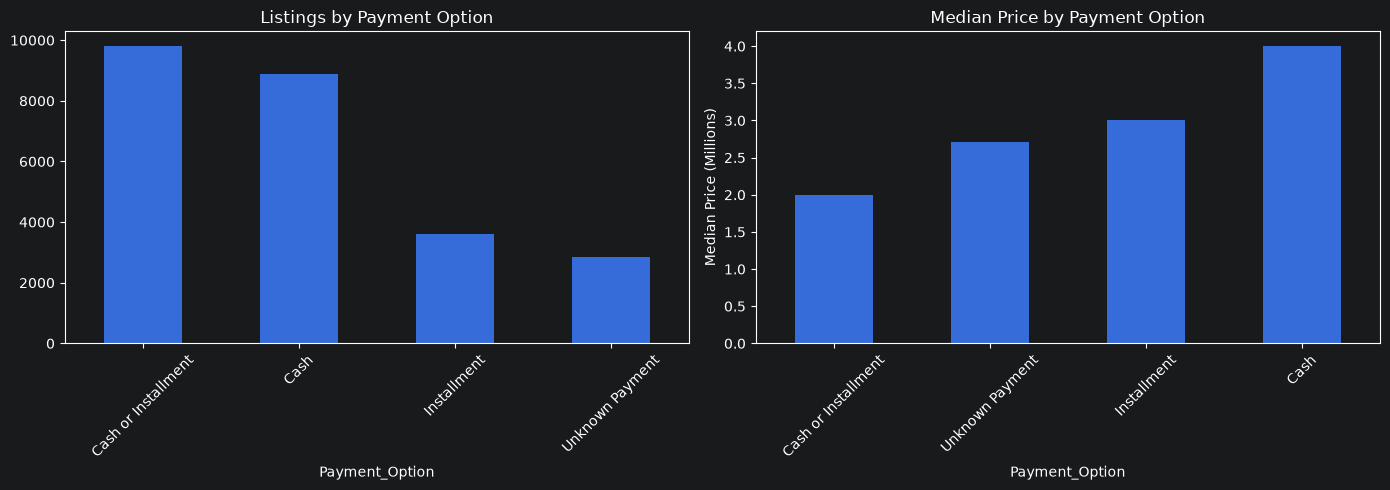

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
plot_df['Payment_Option'].value_counts().head(12).plot(kind='bar', ax=axes[0])
axes[0].set_title('Listings by Payment Option')
axes[0].tick_params(axis='x', rotation=45)
plot_df.groupby('Payment_Option')['Price_Millions'].median().sort_values().tail(12).plot(kind='bar', ax=axes[1])
axes[1].set_title('Median Price by Payment Option')
axes[1].set_ylabel('Median Price (Millions)')
axes[1].tick_params(axis='x', rotation=45)
plt.tight_layout()
plt.show()


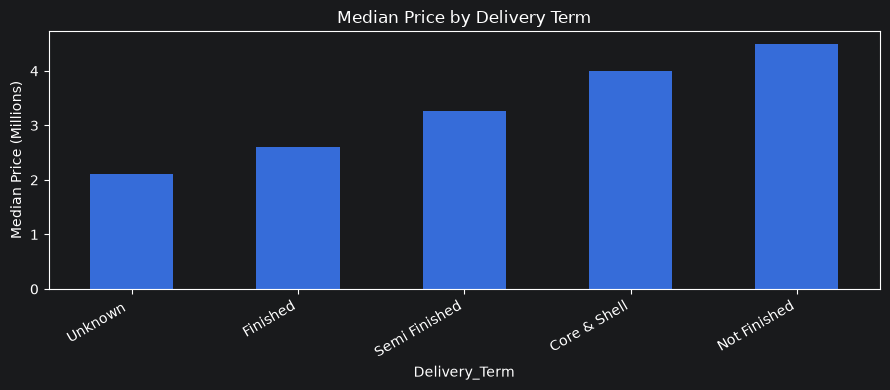

In [24]:
delivery_price = plot_df.groupby('Delivery_Term')['Price_Millions'].median().sort_values()
plt.figure(figsize=(9, 4))
delivery_price.plot(kind='bar')
plt.title('Median Price by Delivery Term')
plt.ylabel('Median Price (Millions)')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()


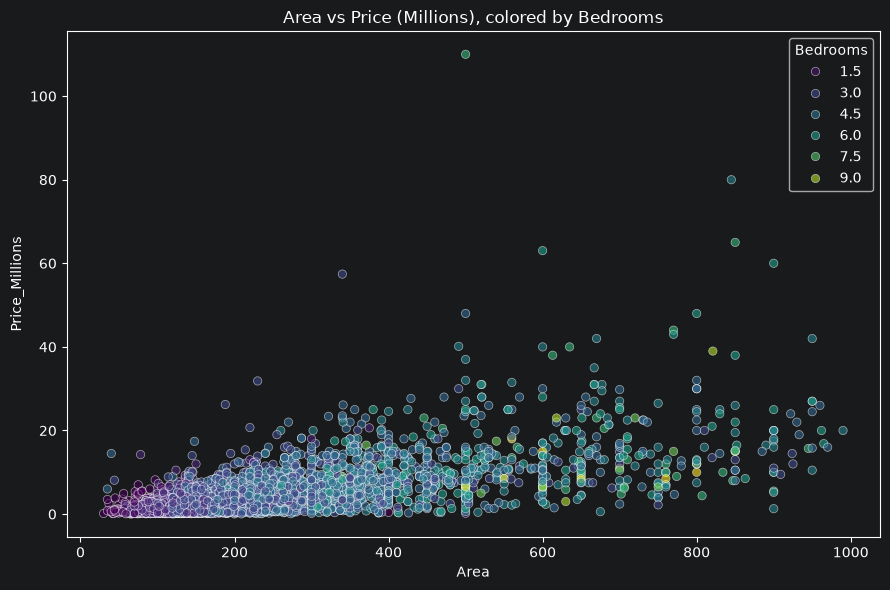

In [25]:
scatter_data = plot_df.dropna(subset=['Area', 'Price']).sample(min(5000, len(plot_df.dropna(subset=['Area', 'Price']))), random_state=42)
plt.figure(figsize=(9, 6))
sns.scatterplot(data=scatter_data, x='Area', y='Price_Millions', hue='Bedrooms', palette='viridis', alpha=0.6)
plt.title('Area vs Price (Millions), colored by Bedrooms')
plt.tight_layout()
plt.show()


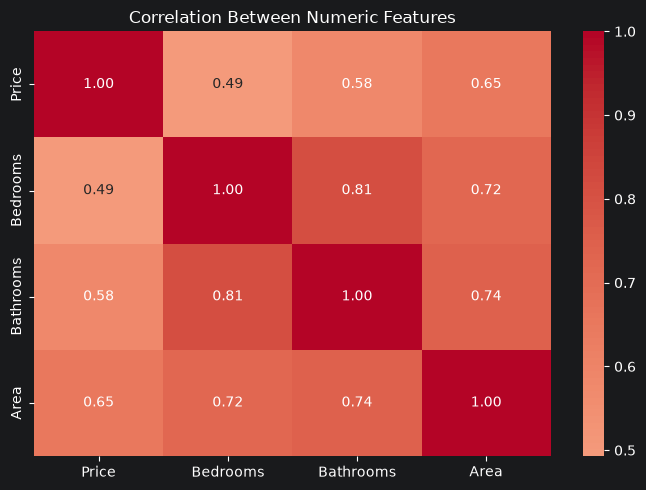

In [26]:
numeric_plot = plot_df[['Price', 'Bedrooms', 'Bathrooms', 'Area']].dropna()
plt.figure(figsize=(7, 5))
sns.heatmap(numeric_plot.corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Between Numeric Features')
plt.tight_layout()
plt.show()


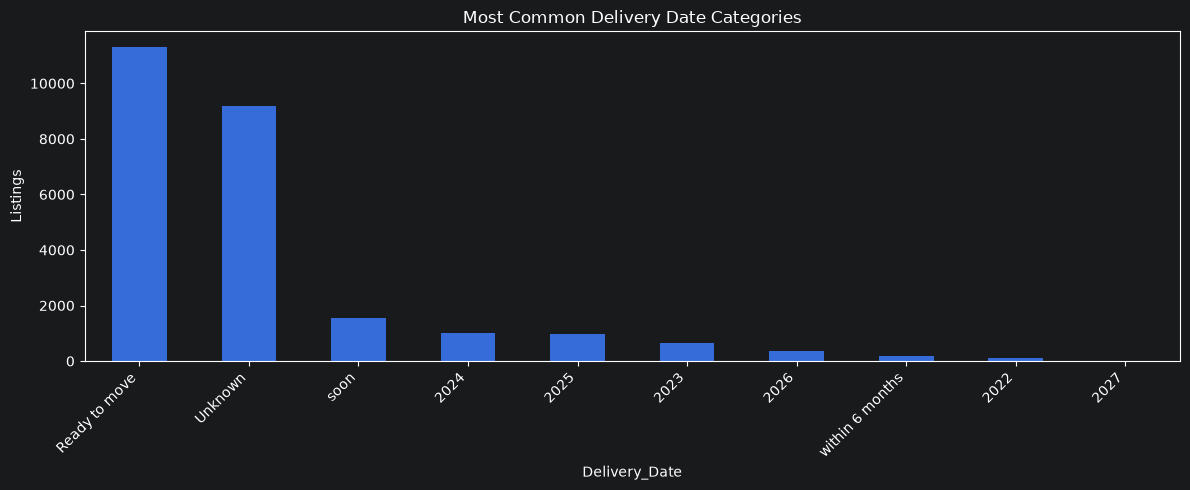

In [27]:
plt.figure(figsize=(12, 5))
plot_df['Delivery_Date'].value_counts().head(15).plot(kind='bar')
plt.title('Most Common Delivery Date Categories')
plt.ylabel('Listings')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [28]:
from sklearn.model_selection import train_test_split
x=df.drop('Price',axis=1)
y=df['Price']
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [29]:
for cl in df.columns:
    print(df[cl].value_counts(dropna=False))

Type
Apartment            7888
Chalet               5960
Stand Alone Villa    4326
Town House           2838
Twin House           1661
Duplex                805
Standalone Villa      593
Penthouse             501
Twin house            457
Studio                226
NaN                   149
Name: count, dtype: int64
Price
3000000.0     286
3500000.0     286
2500000.0     278
2000000.0     244
1500000.0     239
             ... 
4523147.0       1
49500000.0      1
6276000.0       1
11950000.0      1
12284000.0      1
Name: count, Length: 4179, dtype: int64
Bedrooms
3      10861
2       5020
4       4873
5       2192
1        933
6        729
NaN      385
7        231
8         80
10        52
9         47
10+        1
Name: count, dtype: int64
Bathrooms
2      8406
3      6879
4      3705
1      3379
5      1702
6       563
NaN     335
7       259
8        93
10       43
9        39
10+       1
Name: count, dtype: int64
Area
120    602
125    556
100    530
150    510
NaN    495
      ..

In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 25404 entries, 0 to 25403
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Type            25255 non-null  str    
 1   Price           25404 non-null  float64
 2   Bedrooms        25019 non-null  str    
 3   Bathrooms       25069 non-null  str    
 4   Area            24909 non-null  str    
 5   Furnished       25356 non-null  str    
 6   Level           25356 non-null  str    
 7   Compound        25299 non-null  str    
 8   Payment_Option  25174 non-null  str    
 9   Delivery_Date   25316 non-null  str    
 10  Delivery_Term   25343 non-null  str    
 11  City            25391 non-null  str    
dtypes: float64(1), str(11)
memory usage: 2.3 MB


In [31]:
for cl in ['Bedrooms','Bathrooms','Area']:
    x_train[cl] = pd.to_numeric(x_train[cl], errors='coerce')
    x_test[cl]  = pd.to_numeric(x_test[cl],  errors='coerce')

In [32]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 20323 entries, 8443 to 23654
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Type            20199 non-null  str    
 1   Bedrooms        20012 non-null  float64
 2   Bathrooms       20049 non-null  float64
 3   Area            19929 non-null  float64
 4   Furnished       20284 non-null  str    
 5   Level           20284 non-null  str    
 6   Compound        20236 non-null  str    
 7   Payment_Option  20140 non-null  str    
 8   Delivery_Date   20249 non-null  str    
 9   Delivery_Term   20269 non-null  str    
 10  City            20312 non-null  str    
dtypes: float64(3), str(8)
memory usage: 1.9 MB


In [33]:
y_train = pd.to_numeric(y_train, errors='coerce')
y_test  = pd.to_numeric(y_test,  errors='coerce')

In [34]:
df['Level'].value_counts(dropna=False)

Level
Unknown    9652
Ground     4351
2          3495
1          3322
3          1981
4           856
5           526
10+         254
6           215
7           204
Highest     168
8           126
10          103
9           103
NaN          48
Name: count, dtype: int64

In [35]:
x_train['Level_is_highest']=(df['Level']=='Highest').astype(int)
x_test['Level_is_highest']=(df['Level']=='Highest').astype(int)

In [36]:
x_train['Level_is_highest'].value_counts()

Level_is_highest
0    20191
1      132
Name: count, dtype: int64

In [37]:
mp={'10+':11,'Ground':0}
x_train['Level']=x_train['Level'].replace(mp)
x_test['Level']=x_test['Level'].replace(mp)

In [38]:
x_train['Level']=pd.to_numeric(x_train['Level'],errors='coerce')
x_test['Level']=pd.to_numeric(x_test['Level'],errors="coerce")

In [39]:
for cl in x_train.select_dtypes(include='string').columns:
    x_train[cl]=x_train[cl].str.strip().str.lower()
    x_test[cl]=x_test[cl].str.strip().str.lower()

In [40]:
for c in x_train.select_dtypes(include='string').columns:
    x_train[c] = x_train[c].replace("unknown", np.nan)
    x_test[c]  = x_test[c].replace("unknown", np.nan)

In [41]:
x_train.isnull().mean().mul(100).round(2).sort_values(ascending=False)

Compound            41.13
Level               38.93
Delivery_Date       36.79
Furnished           31.27
Delivery_Term       18.04
Area                 1.94
Bedrooms             1.53
Bathrooms            1.35
Payment_Option       0.90
Type                 0.61
City                 0.05
Level_is_highest     0.00
dtype: float64

In [42]:
df['Delivery_Date'].value_counts(dropna=False)

Delivery_Date
Ready to move      11307
Unknown             9184
soon                1548
2024                1000
2025                 957
2023                 654
2026                 360
within 6 months      180
2022                 122
NaN                   88
2027                   4
Name: count, dtype: int64

In [43]:
x_train['Delivery_Date'] = x_train['Delivery_Date'].fillna('unknown')
x_test['Delivery_Date'] = x_test['Delivery_Date'].fillna('unknown')

In [44]:
x_train.describe()

,Bedrooms,Bathrooms,Area,Level,Level_is_highest
count,20012.000000,20049.000000,19929.000000,12411.000000,20323.000000
mean,3.266190,2.837099,231.240225,1.982113,0.006495
std,1.224878,1.368613,161.599492,2.214814,0.080332
min,1.000000,1.000000,10.000000,0.000000,0.000000
25%,3.000000,2.000000,125.000000,0.000000,0.000000
50%,3.000000,3.000000,178.000000,2.000000,0.000000
75%,4.000000,4.000000,277.000000,3.000000,0.000000
max,10.000000,10.000000,998.000000,11.000000,1.000000


In [45]:
from sklearn.impute import SimpleImputer
imputer=SimpleImputer(missing_values=np.nan,strategy='median')

for col in ['Bedrooms','Bathrooms','Area']:
    x_train[col]=imputer.fit_transform(x_train[[col]])
    x_test[col]=imputer.transform(x_test[[col]])

In [46]:
x_train[x_train['Level'].isnull()]['Type'].value_counts()

Type
stand alone villa    3478
town house           1995
twin house           1461
chalet                648
standalone villa      184
penthouse              69
apartment              35
duplex                 32
studio                  9
Name: count, dtype: int64

In [47]:
x_train['Type'] = x_train['Type'].replace('standalone villa', 'stand alone villa')
x_test['Type']  = x_test['Type'].replace('standalone villa', 'stand alone villa')

<BarContainer object of 7 artists>

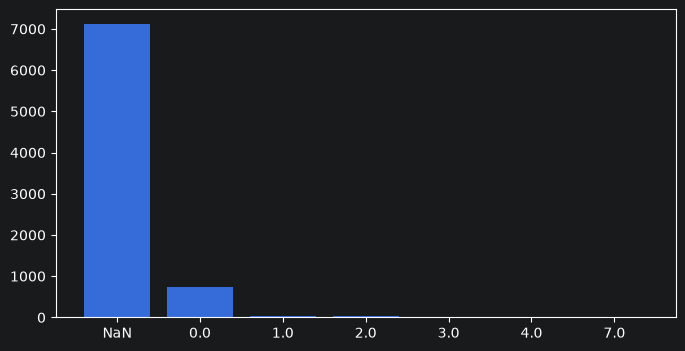

In [48]:
counts = x_train[x_train['Type'].isin(['stand alone villa', 'town house', 'twin house'])]['Level'].value_counts(dropna=False)
labels = counts.index.astype(str).fillna('NaN')

plt.figure(figsize=(8, 4))
plt.bar(labels, counts.values)

In [49]:
counts

Level
NaN    7118
0.0     745
1.0      35
2.0      35
3.0       5
4.0       2
7.0       1
Name: count, dtype: int64

In [50]:
x_train['level_missing']=(x_train['Type'].isin(['stand alone villa', 'town house', 'twin house'])).astype(int)
x_test['level_missing']=(x_test['Type'].isin(['stand alone villa', 'town house', 'twin house'])).astype(int)

In [51]:
x_train.loc[x_train['level_missing'] == 1, 'Level'] = np.nan
x_test.loc[x_test['level_missing'] == 1, 'Level']   = np.nan

In [52]:
x_train[['Level']] = imputer.fit_transform(x_train[['Level']])
x_test[['Level']]  = imputer.transform(x_test[['Level']])

In [53]:
x_train.isnull().mean().mul(100).round(2).sort_values(ascending=False)

Compound            41.13
Furnished           31.27
Delivery_Term       18.04
Payment_Option       0.90
Type                 0.61
City                 0.05
Area                 0.00
Bedrooms             0.00
Bathrooms            0.00
Delivery_Date        0.00
Level                0.00
Level_is_highest     0.00
level_missing        0.00
dtype: float64

In [54]:
x_train.reset_index(drop=True,inplace=True)
x_test.reset_index(drop=True,inplace=True)
x_train.head()

,Type,Bedrooms,Bathrooms,Area,Furnished,Level,Compound,Payment_Option,Delivery_Date,Delivery_Term,City,Level_is_highest,level_missing
0,apartment,3.0,3.0,230.0,no,2.0,NaN,installment,ready to move,semi finished,shorouk city,0,0
1,stand alone villa,4.0,3.0,210.0,no,2.0,NaN,cash or installment,ready to move,finished,new cairo - el tagamoa,0,1
2,twin house,4.0,4.0,320.0,no,2.0,mivida,cash,ready to move,finished,new cairo - el tagamoa,0,1
3,duplex,3.0,3.0,290.0,no,0.0,NaN,installment,ready to move,semi finished,6th of october,0,0
4,apartment,3.0,3.0,147.0,NaN,1.0,NaN,unknown payment,unknown,NaN,new cairo - el tagamoa,0,0


In [55]:
for col in ['Compound','Delivery_Term','Furnished']:
    print(x_train[col].value_counts(dropna=False))

Compound
NaN                          8358
madinaty                      848
mountain view north coast     583
hyde park new cairo           363
rehab city                    322
                             ... 
battersea                       1
siela resort                    1
mena 3                          1
kreir paradise                  1
venus                           1
Name: count, Length: 527, dtype: int64
Delivery_Term
finished         10548
semi finished     4047
NaN               3667
not finished      1355
core & shell       706
Name: count, dtype: int64
Furnished
no     12182
NaN     6356
yes     1785
Name: count, dtype: int64


In [56]:
for col in ['Compound', 'Furnished', 'Delivery_Term']:
    x_train[col] = x_train[col].fillna('unknown')
    x_test[col]  = x_test[col].fillna('unknown')

In [57]:
for cl in ['Payment_Option','City','Type']:
    print(x_train[cl].value_counts(dropna=False))

Payment_Option
cash or installment    7812
cash                   7084
installment            2909
unknown payment        2335
NaN                     183
Name: count, dtype: int64
City
new cairo - el tagamoa    5096
north coast               4638
sheikh zayed              1714
6th of october            1326
ain sukhna                1237
                          ... 
talkha                       1
saft el laban                1
manzala                      1
dhahria                      1
schutz                       1
Name: count, Length: 170, dtype: int64
Type
apartment            6289
chalet               4755
stand alone villa    3948
town house           2301
twin house           1692
duplex                635
penthouse             405
studio                174
NaN                   124
Name: count, dtype: int64


In [58]:
x_train['Payment_Option'] = x_train['Payment_Option'].replace('unknown payment',np.nan)
x_test['Payment_Option']  = x_test['Payment_Option'].replace('unknown payment', np.nan)

In [59]:
x_train['Payment_Option'].isnull().mean()*100

np.float64(12.3899030654923)

In [60]:
x_train['Payment_Option']=x_train['Payment_Option'].fillna('unknown')
x_test['Payment_Option']=x_test['Payment_Option'].fillna('unknown')

In [61]:
imputer=SimpleImputer(missing_values=np.nan,strategy='most_frequent')
for cl in ['City','Type']:
    x_train[[cl]]=imputer.fit_transform(x_train[[cl]])
    x_test[[cl]]=imputer.transform(x_test[[cl]])

In [62]:
x_train.isnull().sum().sort_values(ascending=False)

Type                0
Bedrooms            0
Bathrooms           0
Area                0
Furnished           0
Level               0
Compound            0
Payment_Option      0
Delivery_Date       0
Delivery_Term       0
City                0
Level_is_highest    0
level_missing       0
dtype: int64

In [63]:
x_test.isnull().sum().sort_values(ascending=False)

Type                0
Bedrooms            0
Bathrooms           0
Area                0
Furnished           0
Level               0
Compound            0
Payment_Option      0
Delivery_Date       0
Delivery_Term       0
City                0
Level_is_highest    0
level_missing       0
dtype: int64

In [64]:
y_train.reset_index(drop=True,inplace=True)
y_test.reset_index(drop=True,inplace=True)

In [65]:
y_train.head()

0     1400000.0
1     6875000.0
2    13500000.0
3     1247000.0
4      270000.0
Name: Price, dtype: float64

In [66]:
col=x_train.select_dtypes(exclude='number').columns
col

Index(['Type', 'Furnished', 'Compound', 'Payment_Option', 'Delivery_Date',
       'Delivery_Term', 'City'],
      dtype='str')

In [67]:
for cl in col:
    print(x_train[col].nunique())

Type                8
Furnished           3
Compound          527
Payment_Option      4
Delivery_Date      10
Delivery_Term       5
City              169
dtype: int64
Type                8
Furnished           3
Compound          527
Payment_Option      4
Delivery_Date      10
Delivery_Term       5
City              169
dtype: int64
Type                8
Furnished           3
Compound          527
Payment_Option      4
Delivery_Date      10
Delivery_Term       5
City              169
dtype: int64
Type                8
Furnished           3
Compound          527
Payment_Option      4
Delivery_Date      10
Delivery_Term       5
City              169
dtype: int64
Type                8
Furnished           3
Compound          527
Payment_Option      4
Delivery_Date      10
Delivery_Term       5
City              169
dtype: int64
Type                8
Furnished           3
Compound          527
Payment_Option      4
Delivery_Date      10
Delivery_Term       5
City              169
dtype: int6

In [68]:
from sklearn.preprocessing import OneHotEncoder

oh=OneHotEncoder(sparse_output=False,handle_unknown='ignore')
trc=oh.fit_transform(x_train[['Type', 'Furnished', 'Payment_Option', 'Delivery_Date', 'Delivery_Term']])
tsc=oh.transform(x_test[['Type', 'Furnished', 'Payment_Option', 'Delivery_Date', 'Delivery_Term']])

In [69]:
dtr=pd.DataFrame(trc,columns=oh.get_feature_names_out(['Type', 'Furnished', 'Payment_Option', 'Delivery_Date', 'Delivery_Term']),index=x_train.index)
dts=pd.DataFrame(tsc,columns=oh.get_feature_names_out(['Type', 'Furnished', 'Payment_Option', 'Delivery_Date', 'Delivery_Term']),index=x_test.index)

In [70]:
x_train=pd.concat([x_train.drop(['Type', 'Furnished', 'Payment_Option', 'Delivery_Date', 'Delivery_Term'],axis=1),dtr],axis=1)
x_test=pd.concat([x_test.drop(['Type', 'Furnished', 'Payment_Option', 'Delivery_Date', 'Delivery_Term'],axis=1),dts],axis=1)

In [71]:
x_train.head()

,Bedrooms,Bathrooms,Area,Level,Compound,City,Level_is_highest,level_missing,Type_apartment,Type_chalet,...,Delivery_Date_2027,Delivery_Date_ready to move,Delivery_Date_soon,Delivery_Date_unknown,Delivery_Date_within 6 months,Delivery_Term_core & shell,Delivery_Term_finished,Delivery_Term_not finished,Delivery_Term_semi finished,Delivery_Term_unknown
0,3.0,3.0,230.0,2.0,unknown,shorouk city,0,0,1.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,4.0,3.0,210.0,2.0,unknown,new cairo - el tagamoa,0,1,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
2,4.0,4.0,320.0,2.0,mivida,new cairo - el tagamoa,0,1,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0
3,3.0,3.0,290.0,0.0,unknown,6th of october,0,0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
4,3.0,3.0,147.0,1.0,unknown,new cairo - el tagamoa,0,0,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0


In [72]:
from sklearn.preprocessing import TargetEncoder
tg=TargetEncoder(target_type='continuous',smooth='auto',random_state=42)
train_te=tg.fit_transform(x_train[['Compound','City']], y_train)
test_te=tg.transform(x_test[['Compound','City']])

x_train['Compound'] = train_te[:, 0]
x_train['City']     = train_te[:, 1]
x_test['Compound']  = test_te[:, 0]
x_test['City']      = test_te[:, 1]

D:\charmPrj\.venv\Lib\site-packages\sklearn\preprocessing\_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


In [73]:
x_train.describe()

,Bedrooms,Bathrooms,Area,Level,Compound,City,Level_is_highest,level_missing,Type_apartment,Type_chalet,...,Delivery_Date_2027,Delivery_Date_ready to move,Delivery_Date_soon,Delivery_Date_unknown,Delivery_Date_within 6 months,Delivery_Term_core & shell,Delivery_Term_finished,Delivery_Term_not finished,Delivery_Term_semi finished,Delivery_Term_unknown
count,20323.000000,20323.000000,20323.000000,20323.000000,2.032300e+04,2.032300e+04,20323.000000,20323.000000,20323.000000,20323.000000,...,20323.000000,20323.000000,20323.00000,20323.000000,20323.000000,20323.000000,20323.000000,20323.000000,20323.000000,20323.000000
mean,3.262117,2.839295,230.208062,2.063426,4.748168e+06,4.830890e+06,0.006495,0.390740,0.315554,0.233971,...,0.000098,0.442651,0.06067,0.367859,0.007135,0.034739,0.519018,0.066673,0.199134,0.180436
std,1.215908,1.359486,160.193582,1.685679,3.558236e+06,1.987882e+06,0.080332,0.487928,0.464747,0.423365,...,0.009920,0.496712,0.23873,0.482235,0.084168,0.183122,0.499650,0.249461,0.399359,0.384560
min,1.000000,1.000000,10.000000,0.000000,2.140278e+05,1.600000e+05,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,3.000000,2.000000,125.000000,1.000000,3.257201e+06,3.864581e+06,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,3.000000,3.000000,178.000000,2.000000,3.295947e+06,4.217635e+06,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.00000,0.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
75%,4.000000,4.000000,273.000000,2.000000,5.263350e+06,6.905009e+06,0.000000,1.000000,1.000000,0.000000,...,0.000000,1.000000,0.00000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000
max,10.000000,10.000000,998.000000,11.000000,3.774469e+07,1.197930e+07,1.000000,1.000000,1.000000,1.000000,...,1.000000,1.000000,1.00000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_23200\902935059.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x_train[cl], vert=False)


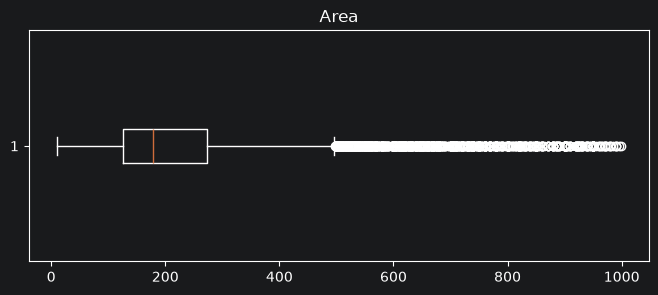

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_23200\902935059.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x_train[cl], vert=False)


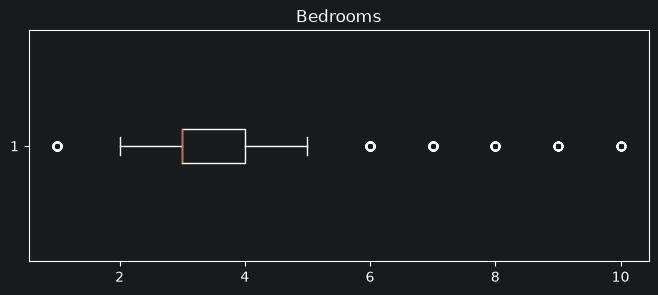

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_23200\902935059.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x_train[cl], vert=False)


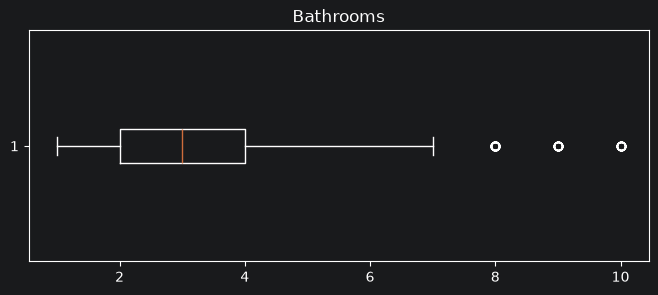

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_23200\902935059.py:5: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(x_train[cl], vert=False)


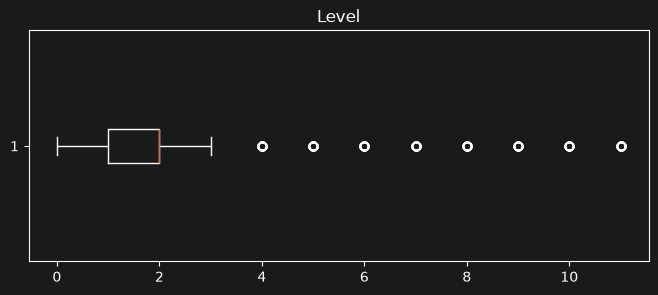

In [74]:
cols = ['Area', 'Bedrooms', 'Bathrooms', 'Level']

for cl in cols:
    plt.figure(figsize=(8, 3))
    plt.boxplot(x_train[cl], vert=False)
    plt.title(cl)
    plt.show()

C:\Users\LAPTOP\AppData\Local\Temp\ipykernel_23200\1849195017.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(y_train/1000000 , vert=False)


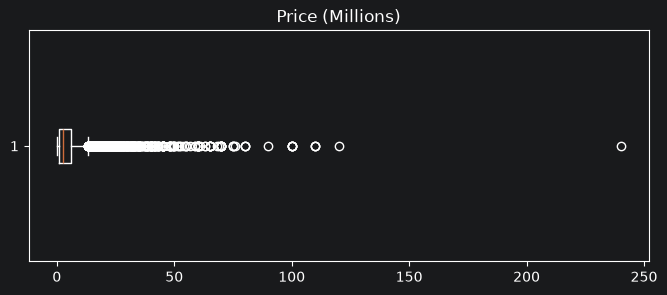

In [75]:
plt.figure(figsize=(8, 3))
plt.boxplot(y_train/1000000 , vert=False)
plt.title('Price (Millions)')
plt.show()

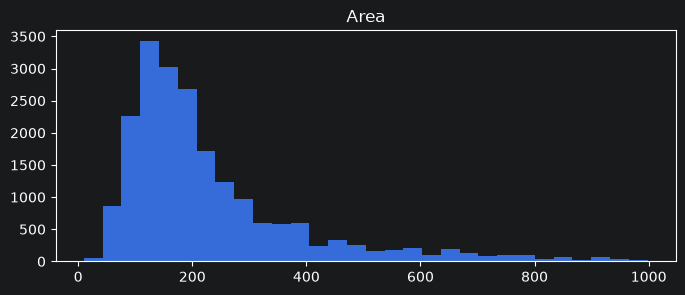

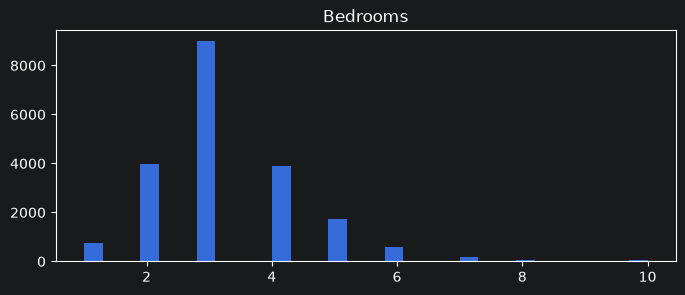

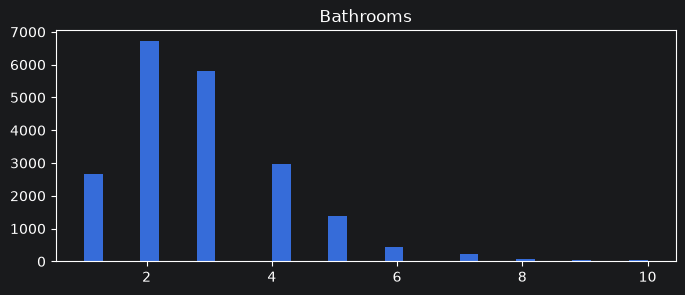

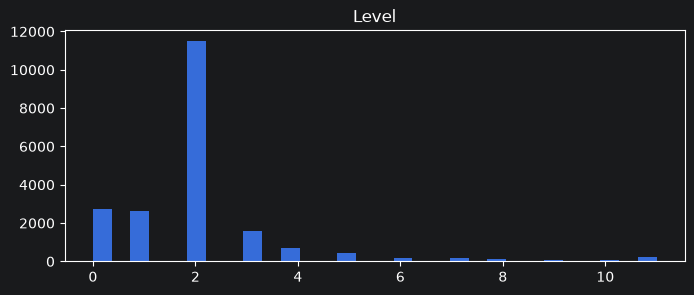

In [76]:
cols = ['Area', 'Bedrooms', 'Bathrooms', 'Level']

for cl in cols:
    plt.figure(figsize=(8, 3))
    plt.hist(x_train[cl], bins=30)
    plt.title(cl)
    plt.show()

In [77]:
from sklearn.ensemble import IsolationForest

check = x_train[['Area', 'Bedrooms', 'Bathrooms', 'Level']].copy()
check['Price'] = y_train
iso = IsolationForest(n_estimators=100, contamination=0.02, random_state=42)
preds = iso.fit_predict(check)
print((preds == 1).sum())
print((preds == -1).sum())

check[preds == -1].head(15)

19916
407


,Area,Bedrooms,Bathrooms,Level,Price
50,175.0,3.0,3.0,6.0,31500000.0
220,178.0,3.0,6.0,2.0,70000000.0
248,800.0,10.0,9.0,2.0,12000000.0
270,850.0,3.0,3.0,2.0,40000000.0
355,700.0,6.0,6.0,2.0,27000000.0
450,178.0,8.0,9.0,2.0,16000000.0
478,178.0,10.0,9.0,2.0,7000000.0
495,540.0,7.0,8.0,2.0,7800000.0
587,178.0,6.0,7.0,2.0,240000000.0
594,500.0,10.0,7.0,2.0,6500000.0


In [78]:
x_train = x_train[preds == 1].reset_index(drop=True)
y_train = y_train[preds == 1].reset_index(drop=True)

x_train.shape,y_train.shape

((19916, 38), (19916,))

In [79]:
(y_train / 1_000_000).describe()

count    19916.000000
mean         4.349983
std          5.018693
min          0.030000
25%          1.100000
50%          2.700000
75%          5.748559
max         69.000000
Name: Price, dtype: float64

In [80]:
print(y_train.quantile(0.01))

150000.0


In [81]:
print((y_train < 200_000).sum())
print((y_train < 300_000).sum())

372
1105


In [82]:
x_train = x_train[y_train>200000].reset_index(drop=True)
y_train = y_train[y_train>200000].reset_index(drop=True)

In [83]:
(y_train / 1_000_000).describe()

count    19500.000000
mean         4.439592
std          5.033901
min          0.202000
25%          1.200000
50%          2.800000
75%          5.862250
max         69.000000
Name: Price, dtype: float64

In [84]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_sc = x_train.copy()
x_test_sc  = x_test.copy()

x_train_sc[['Bedrooms', 'Bathrooms', 'Area', 'Level', 'Compound', 'City']] = scaler.fit_transform(x_train[['Bedrooms', 'Bathrooms', 'Area', 'Level', 'Compound', 'City']])
x_test_sc[['Bedrooms', 'Bathrooms', 'Area', 'Level', 'Compound', 'City']]  = scaler.transform(x_test[['Bedrooms', 'Bathrooms', 'Area', 'Level', 'Compound', 'City']])

x_train_sc[['Bedrooms', 'Bathrooms', 'Area', 'Level', 'Compound', 'City']].describe().round(2)

,Bedrooms,Bathrooms,Area,Level,Compound,City
count,19500.00,19500.00,19500.00,19500.00,19500.00,19500.00
mean,0.00,0.00,0.00,0.00,-0.00,0.00
std,1.00,1.00,1.00,1.00,1.00,1.00
min,-2.03,-1.45,-1.45,-1.23,-1.34,-2.36
25%,-0.20,-0.64,-0.67,-0.63,-0.43,-0.49
50%,-0.20,0.17,-0.32,-0.03,-0.41,-0.31
75%,0.72,0.17,0.30,-0.03,0.17,1.05
max,6.22,5.86,5.18,5.32,9.98,3.61


In [85]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_absolute_error, root_mean_squared_error

lr = LinearRegression()
lr.fit(x_train_sc, y_train)

y_pred_train = lr.predict(x_train_sc)
y_pred_test  = lr.predict(x_test_sc)

print("Train R2:", round(r2_score(y_train, y_pred_train), 4))
print("Test  R2:", round(r2_score(y_test, y_pred_test), 4))
print("Test MAE:", f"{mean_absolute_error(y_test, y_pred_test):,.0f}")
print("Test RMSE:", f"{root_mean_squared_error(y_test, y_pred_test):,.0f}")

Train R2: 0.5809
Test  R2: 0.467
Test MAE: 2,215,531
Test RMSE: 5,081,292


In [86]:
results = []

def evaluate(name, model, x_tr, x_ts):
    model.fit(x_tr, y_train)
    pred_tr = model.predict(x_tr)
    pred_ts = model.predict(x_ts)

    results.append({
        'Model': name,
        'Train_R2': round(r2_score(y_train, pred_tr), 4),
        'Test_R2':  round(r2_score(y_test, pred_ts), 4),
        'Test_MAE': round(mean_absolute_error(y_test, pred_ts)),
        'Test_RMSE': round(root_mean_squared_error(y_test, pred_ts))
    })

In [87]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

evaluate("LinearRegression", LinearRegression(), x_train_sc, x_test_sc)
evaluate("Ridge",            Ridge(alpha=10.0),  x_train_sc, x_test_sc)
evaluate("Lasso",            Lasso(alpha=1000.0, max_iter=5000), x_train_sc, x_test_sc)
evaluate("ElasticNet",       ElasticNet(alpha=0.1, max_iter=5000), x_train_sc, x_test_sc)

pd.DataFrame(results)

,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
0,LinearRegression,0.5809,0.4670,2215531,5081292
1,Ridge,0.5808,0.4669,2215528,5081732
2,Lasso,0.5808,0.4669,2215057,5081582
3,ElasticNet,0.5775,0.4613,2216439,5108368


In [88]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.tree import DecisionTreeRegressor

evaluate("KNN (k=10)",KNeighborsRegressor(n_neighbors=10),x_train_sc, x_test_sc)

evaluate("DecisionTree (Depth=10)", DecisionTreeRegressor(max_depth=10, random_state=42), x_train,x_test)

pd.DataFrame(results)

,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
0,LinearRegression,0.5809,0.4670,2215531,5081292
1,Ridge,0.5808,0.4669,2215528,5081732
2,Lasso,0.5808,0.4669,2215057,5081582
3,ElasticNet,0.5775,0.4613,2216439,5108368
4,KNN (k=10),0.6948,0.4959,1965076,4941706
5,DecisionTree (Depth=10),0.7844,0.4309,2081953,5250314


In [89]:
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

evaluate("RandomForest",RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1),                        x_train, x_test)
evaluate("GradientBoosting",GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42), x_train, x_test)
evaluate("HistGradientBoosting", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, random_state=42),    x_train, x_test)

pd.DataFrame(results)

,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
0,LinearRegression,0.5809,0.4670,2215531,5081292
1,Ridge,0.5808,0.4669,2215528,5081732
2,Lasso,0.5808,0.4669,2215057,5081582
3,ElasticNet,0.5775,0.4613,2216439,5108368
4,KNN (k=10),0.6948,0.4959,1965076,4941706
5,DecisionTree (Depth=10),0.7844,0.4309,2081953,5250314
6,RandomForest,0.9547,0.5210,1778614,4816966
7,GradientBoosting,0.7848,0.5002,1908233,4920381
8,HistGradientBoosting,0.7625,0.5318,1860025,4762376


In [90]:
from sklearn.svm import SVR
from sklearn.model_selection import GridSearchCV

y_scaler = StandardScaler()
y_train_sc = y_scaler.fit_transform(y_train.values.reshape(-1, 1)).ravel()

idx = np.random.RandomState(42).choice(len(x_train_sc), size=4000, replace=False)
x_sub = x_train_sc.iloc[idx]
y_sub = y_train_sc[idx]

param_grid = {
    'C': [1, 10, 50],
    'epsilon': [0.05, 0.2],
    'gamma': ['scale', 0.05]
}

grid = GridSearchCV(
    estimator=SVR(kernel='rbf'),
    param_grid=param_grid,
    cv=3,
    scoring='r2',
    n_jobs=-1,
    verbose=1
)

grid.fit(x_sub, y_sub)

print(grid.best_params_)
print(round(grid.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
{'C': 1, 'epsilon': 0.2, 'gamma': 'scale'}
0.6248


In [91]:
best_svr = SVR(kernel='rbf', **grid.best_params_)
best_svr.fit(x_train_sc, y_train_sc)

pred_tr_sc = best_svr.predict(x_train_sc)
pred_ts_sc = best_svr.predict(x_test_sc)

pred_tr = y_scaler.inverse_transform(pred_tr_sc.reshape(-1, 1)).ravel()
pred_ts = y_scaler.inverse_transform(pred_ts_sc.reshape(-1, 1)).ravel()

results.append({
    'Model': f"SVR {grid.best_params_}",
    'Train_R2': round(r2_score(y_train, pred_tr), 4),
    'Test_R2':  round(r2_score(y_test, pred_ts), 4),
    'Test_MAE': round(mean_absolute_error(y_test, pred_ts)),
    'Test_RMSE': round(root_mean_squared_error(y_test, pred_ts))
})

pd.DataFrame(results)

,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
0,LinearRegression,0.5809,0.4670,2215531,5081292
1,Ridge,0.5808,0.4669,2215528,5081732
2,Lasso,0.5808,0.4669,2215057,5081582
3,ElasticNet,0.5775,0.4613,2216439,5108368
4,KNN (k=10),0.6948,0.4959,1965076,4941706
5,DecisionTree (Depth=10),0.7844,0.4309,2081953,5250314
6,RandomForest,0.9547,0.5210,1778614,4816966
7,GradientBoosting,0.7848,0.5002,1908233,4920381
8,HistGradientBoosting,0.7625,0.5318,1860025,4762376
9,"SVR {'C': 1, 'epsilon': 0.2, 'gamma': 'scale'}",0.6713,0.4746,1952531,5044974


In [92]:
from sklearn.model_selection import cross_val_score

models_cv = {
    "LinearRegression":     (LinearRegression(), x_train_sc),
    "KNN (k=10)":           (KNeighborsRegressor(n_neighbors=10), x_train_sc),
    "RandomForest":         (RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), x_train),
    "GradientBoosting":     (GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=5, random_state=42), x_train),
    "HistGradientBoosting": (HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, random_state=42), x_train),
}

for name, (model, data) in models_cv.items():
    scores = cross_val_score(model, data, y_train, cv=5, scoring='r2', n_jobs=-1)
    print(f"{name:22s} | CV R2: {scores.mean():.4f} ± {scores.std():.4f}")

LinearRegression       | CV R2: 0.5803 ± 0.0235
KNN (k=10)             | CV R2: 0.6254 ± 0.0226
RandomForest           | CV R2: 0.6798 ± 0.0236
GradientBoosting       | CV R2: 0.6787 ± 0.0248
HistGradientBoosting   | CV R2: 0.6770 ± 0.0242


In [93]:
from sklearn.ensemble import ExtraTreesRegressor

y_train_log = np.log1p(y_train)

def evaluate_log(name, model, x_tr, x_ts):
    model.fit(x_tr, y_train_log)
    pred_tr = np.expm1(model.predict(x_tr))
    pred_ts = np.expm1(model.predict(x_ts))

    results.append({
        'Model': name,
        'Train_R2': round(r2_score(y_train, pred_tr), 4),
        'Test_R2':  round(r2_score(y_test, pred_ts), 4),
        'Test_MAE': round(mean_absolute_error(y_test, pred_ts)),
        'Test_RMSE': round(root_mean_squared_error(y_test, pred_ts))
    })

evaluate("ExtraTrees",ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1), x_train, x_test)
evaluate_log("RandomForest (log)",RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1), x_train, x_test)
evaluate_log("HistGradientBoosting (log)", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.1, random_state=42), x_train, x_test)
evaluate_log("ExtraTrees (log)",ExtraTreesRegressor(n_estimators=100, random_state=42, n_jobs=-1), x_train, x_test)

pd.DataFrame(results).sort_values('Test_MAE')

,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
6,RandomForest,0.9547,0.5210,1778614,4816966
11,RandomForest (log),0.9184,0.4852,1791439,4993483
10,ExtraTrees,0.9975,0.4909,1814049,4966026
13,ExtraTrees (log),0.9973,0.4747,1818281,5044178
8,HistGradientBoosting,0.7625,0.5318,1860025,4762376
12,HistGradientBoosting (log),0.6831,0.5002,1866728,4920280
7,GradientBoosting,0.7848,0.5002,1908233,4920381
9,"SVR {'C': 1, 'epsilon': 0.2, 'gamma': 'scale'}",0.6713,0.4746,1952531,5044974
4,KNN (k=10),0.6948,0.4959,1965076,4941706
5,DecisionTree (Depth=10),0.7844,0.4309,2081953,5250314


In [94]:
from xgboost import XGBRegressor
from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor

xgb = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1)
lgb = LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, n_jobs=-1, verbose=-1)
cat = CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, random_seed=42, verbose=0)

evaluate("XGBoost",  xgb, x_train, x_test)
evaluate("LightGBM", lgb, x_train, x_test)
evaluate("CatBoost", cat, x_train, x_test)

evaluate_log("XGBoost (log)",  XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6, random_state=42, n_jobs=-1), x_train, x_test)
evaluate_log("LightGBM (log)", LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, n_jobs=-1, verbose=-1), x_train, x_test)
evaluate_log("CatBoost (log)", CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, random_seed=42, verbose=0), x_train, x_test)

pd.DataFrame(results).sort_values('Test_MAE')

,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
6,RandomForest,0.9547,0.5210,1778614,4816966
11,RandomForest (log),0.9184,0.4852,1791439,4993483
10,ExtraTrees,0.9975,0.4909,1814049,4966026
13,ExtraTrees (log),0.9973,0.4747,1818281,5044178
15,LightGBM,0.7865,0.5313,1853747,4764986
14,XGBoost,0.8043,0.5120,1856240,4861982
8,HistGradientBoosting,0.7625,0.5318,1860025,4762376
12,HistGradientBoosting (log),0.6831,0.5002,1866728,4920280
17,XGBoost (log),0.7056,0.4815,1881125,5011598
18,LightGBM (log),0.6767,0.4923,1891489,4958884


In [95]:
from sklearn.ensemble import StackingRegressor

rf_tuned = RandomForestRegressor(
    n_estimators=200,
    max_depth=20,
    min_samples_leaf=3,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)
evaluate("RandomForest (Tuned)", rf_tuned, x_train, x_test)

estimators = [
    ('hgb', HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, random_state=42)),
    ('lgb', LGBMRegressor(n_estimators=300, learning_rate=0.05, random_state=42, n_jobs=-1, verbose=-1)),
    ('cat', CatBoostRegressor(iterations=500, learning_rate=0.05, depth=6, random_seed=42, verbose=0)),
    ('rf',  rf_tuned)
]

stack = StackingRegressor(
    estimators=estimators,
    final_estimator=Ridge(alpha=10.0),
    cv=5,
    n_jobs=-1
)

evaluate("Stacking (HGB+LGB+Cat+RF)", stack, x_train, x_test)

pd.DataFrame(results).sort_values('Test_R2', ascending=False).head(10)

,Model,Train_R2,Test_R2,Test_MAE,Test_RMSE
20,RandomForest (Tuned),0.8624,0.5339,1760024,4751768
21,Stacking (HGB+LGB+Cat+RF),0.8327,0.5336,1790389,4753095
8,HistGradientBoosting,0.7625,0.5318,1860025,4762376
15,LightGBM,0.7865,0.5313,1853747,4764986
6,RandomForest,0.9547,0.5210,1778614,4816966
16,CatBoost,0.7406,0.5187,1898149,4828699
14,XGBoost,0.8043,0.5120,1856240,4861982
7,GradientBoosting,0.7848,0.5002,1908233,4920381
12,HistGradientBoosting (log),0.6831,0.5002,1866728,4920280
4,KNN (k=10),0.6948,0.4959,1965076,4941706


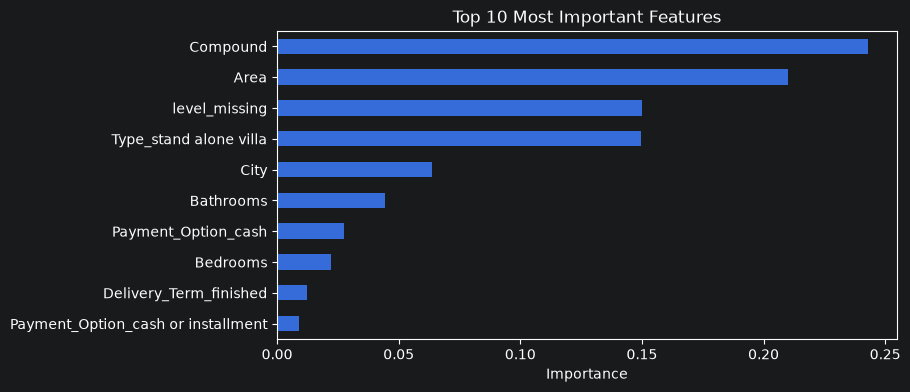

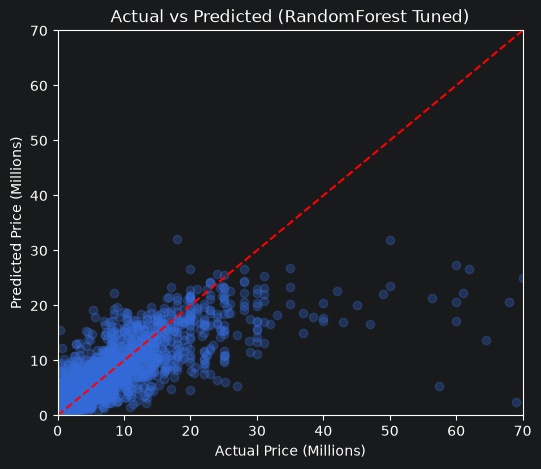

In [96]:
imp = pd.Series(rf_tuned.feature_importances_, index=x_train.columns).sort_values(ascending=False).head(10)

plt.figure(figsize=(8, 4))
imp[::-1].plot(kind='barh')
plt.title('Top 10 Most Important Features')
plt.xlabel('Importance')
plt.show()

pred_rf = rf_tuned.predict(x_test)

plt.figure(figsize=(6, 5))
plt.scatter(y_test / 1_000_000, pred_rf / 1_000_000, alpha=0.3)
plt.plot([0, 70], [0, 70], 'r--')
plt.xlim(0, 70)
plt.ylim(0, 70)
plt.xlabel('Actual Price (Millions)')
plt.ylabel('Predicted Price (Millions)')
plt.title('Actual vs Predicted (RandomForest Tuned)')
plt.show()

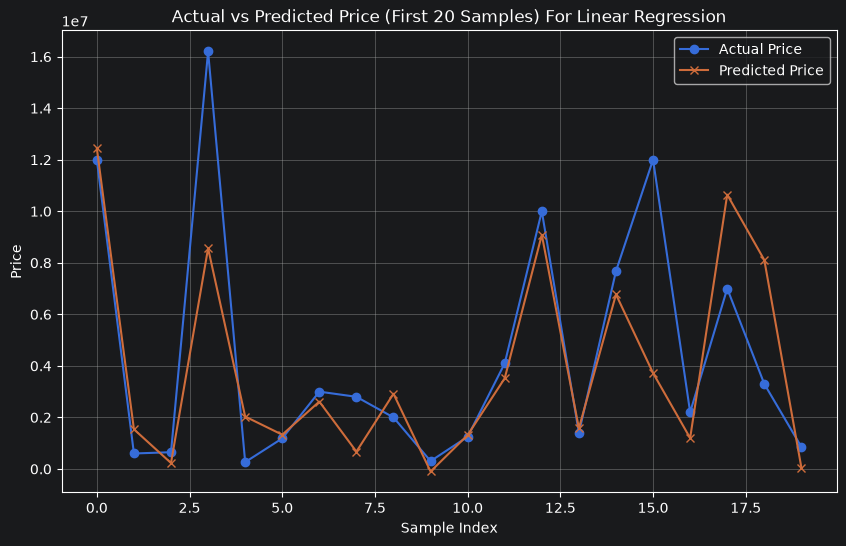

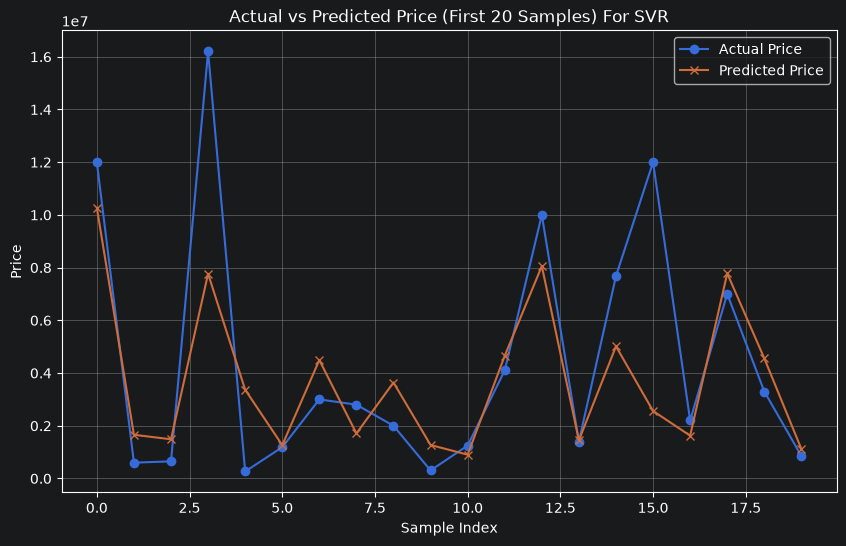

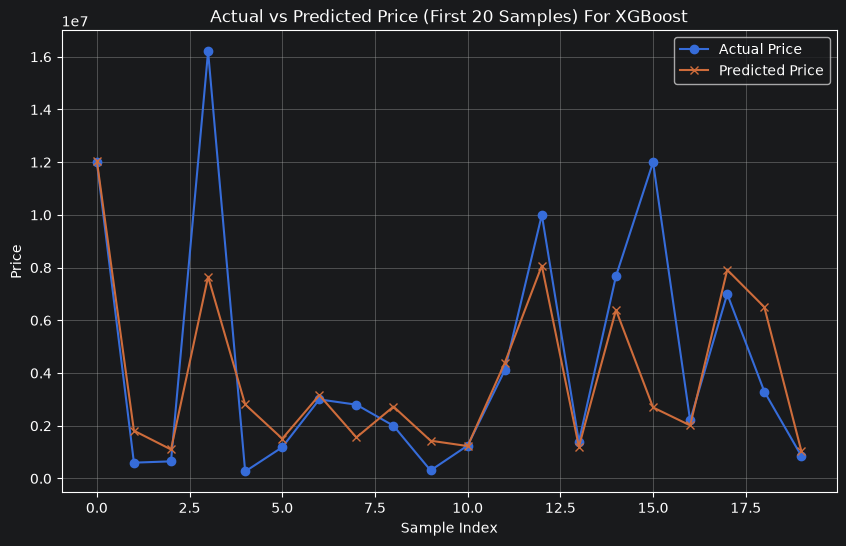

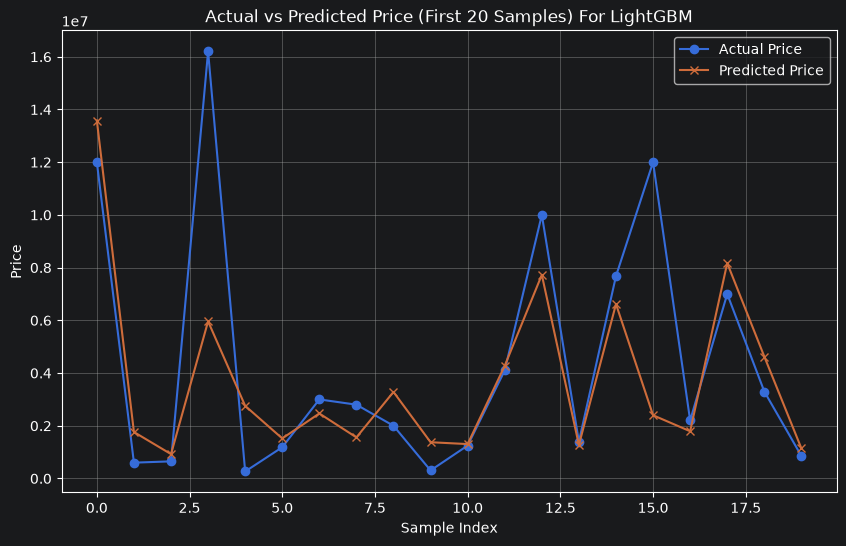

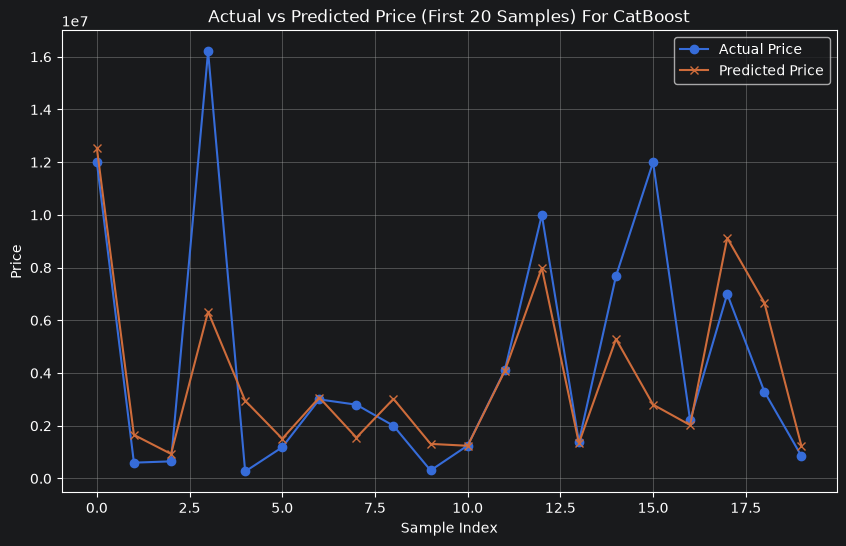

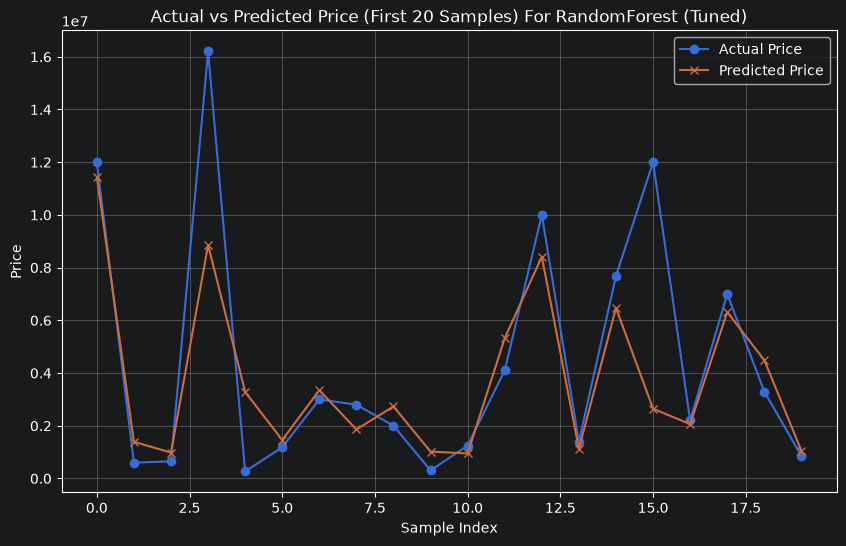

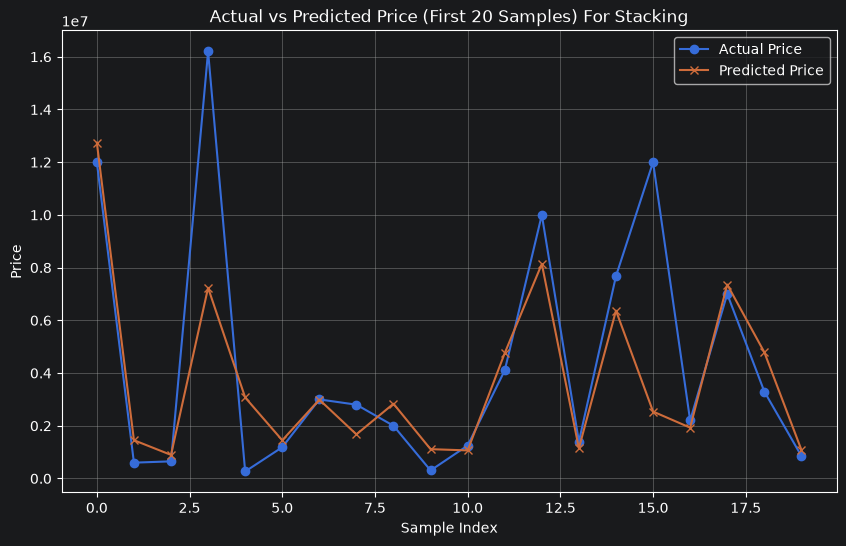

In [97]:
models_list = [
    ('Linear Regression', lr, x_test_sc, False),
    ('SVR', best_svr, x_test_sc, True),
    ('XGBoost', xgb, x_test, False),
    ('LightGBM', lgb, x_test, False),
    ('CatBoost', cat, x_test, False),
    ('RandomForest (Tuned)', rf_tuned, x_test, False),
    ('Stacking', stack, x_test, False)
]

y_test_plot = y_test.values[:20]

for model_name, model, X_test, is_scaled_y in models_list:
    y_pred_plot = model.predict(X_test[:20])
    if is_scaled_y:
        y_pred_plot = y_scaler.inverse_transform(y_pred_plot.reshape(-1, 1)).ravel()

    plt.figure(figsize=(10, 6))
    plt.plot(range(20), y_test_plot, label='Actual Price', marker='o')
    plt.plot(range(20), y_pred_plot, label='Predicted Price', marker='x')
    plt.xlabel('Sample Index')
    plt.ylabel('Price')
    plt.title('Actual vs Predicted Price (First 20 Samples) For ' + model_name)
    plt.legend()
    plt.grid()
    plt.show()

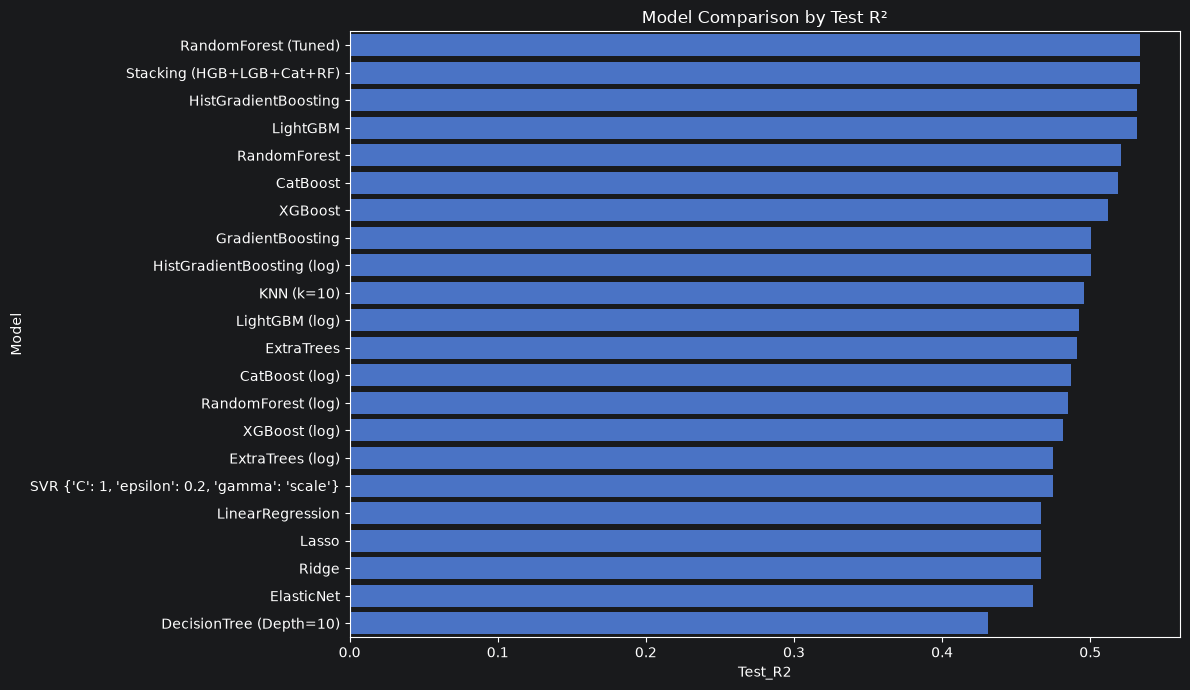

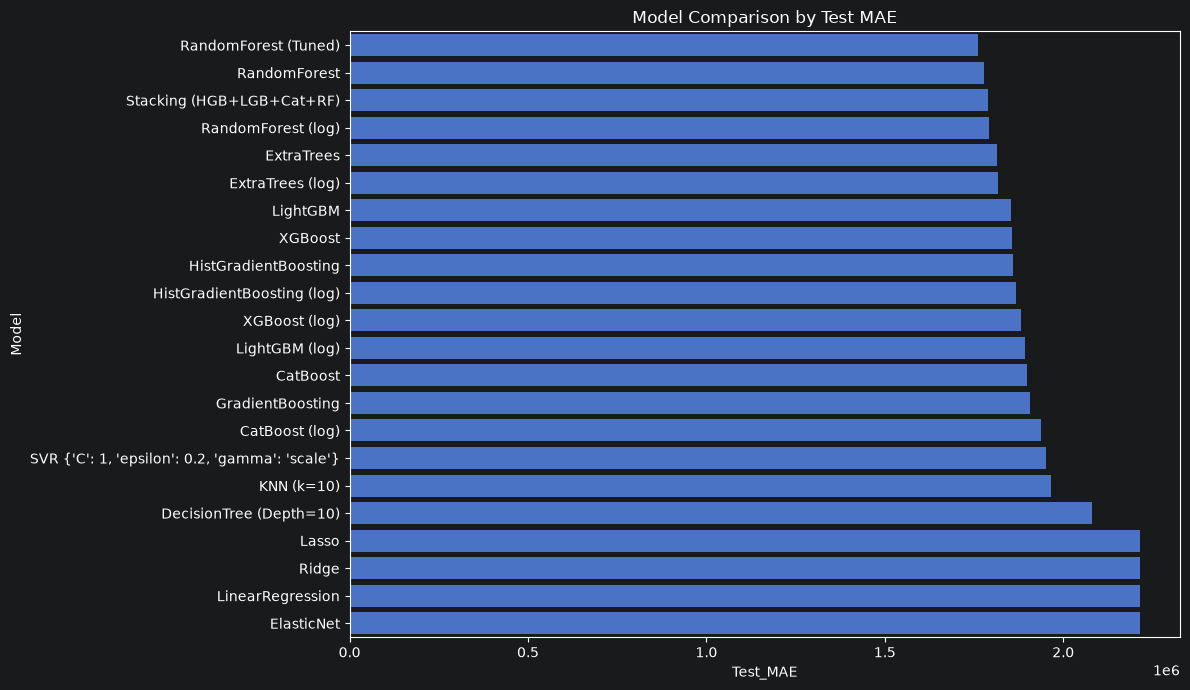

In [98]:
results_df = pd.DataFrame(results).drop_duplicates(subset='Model', keep='last')
if not results_df.empty:
    results_sorted = results_df.sort_values('Test_R2', ascending=False)
    plt.figure(figsize=(12, 7))
    sns.barplot(data=results_sorted, x='Test_R2', y='Model')
    plt.title('Model Comparison by Test R²')
    plt.tight_layout()
    plt.show()

    results_mae = results_df.sort_values('Test_MAE')
    plt.figure(figsize=(12, 7))
    sns.barplot(data=results_mae, x='Test_MAE', y='Model')
    plt.title('Model Comparison by Test MAE')
    plt.tight_layout()
    plt.show()


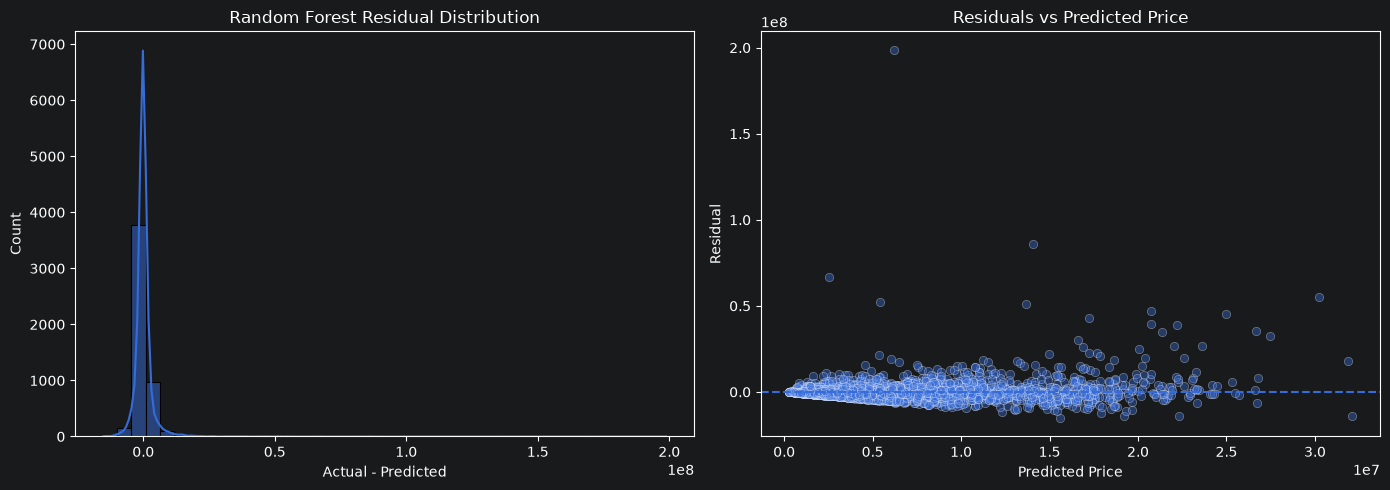

In [99]:
pred_rf_test = rf_tuned.predict(x_test)
residuals_rf = y_test - pred_rf_test

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(residuals_rf, bins=40, kde=True, ax=axes[0])
axes[0].set_title('Random Forest Residual Distribution')
axes[0].set_xlabel('Actual - Predicted')
sns.scatterplot(x=pred_rf_test, y=residuals_rf, alpha=0.4, ax=axes[1])
axes[1].axhline(0, linestyle='--')
axes[1].set_title('Residuals vs Predicted Price')
axes[1].set_xlabel('Predicted Price')
axes[1].set_ylabel('Residual')
plt.tight_layout()
plt.show()


In [101]:
import gradio as gr
import pandas as pd
import numpy as np

deployment_model = stack
feature_columns = x_train.columns.tolist()

def predict_house_price(input_df):
    if not isinstance(input_df, pd.DataFrame):
        input_df = pd.DataFrame(input_df, columns=feature_columns)
    input_df = input_df.reindex(columns=feature_columns)
    prediction = deployment_model.predict(input_df)[0]
    return f"Predicted house price: {prediction:,.0f} EGP"

demo = gr.Interface(
    fn=predict_house_price,
    inputs=gr.Dataframe(
        headers=feature_columns,
        datatype="number",
        row_count=(1, 1),
        col_count=(len(feature_columns), "fixed"),
        label="Enter one row of preprocessed features (columns in exact order)"
    ),
    outputs=gr.Textbox(label="Predicted Price"),
    title="Egypt House Price Prediction",
    description="Enter a single row using the feature columns from the notebook's final preprocessed x_train matrix."
)

demo.launch(share=True)

D:\charmPrj\.venv\Lib\site-packages\gradio\components\dataframe.py:192: UserWarning: The `col_count` parameter is deprecated and will be removed. Please use `column_count` instead.
  warnings.warn(


* Running on local URL:  http://127.0.0.1:7861
* Running on public URL: https://d3798ce98767256010.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
